In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sqlite3
import glob
import os

In [6]:
files = glob.glob(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Raw/*.csv")

print("Number of files:", len(files))

Number of files: 12


In [7]:
monthly_data = []

for file in files:
    data = pd.read_csv(file)

# Standardise column names
    data.columns = data.columns.str.strip().str.lower().str.replace("&", "and").str.replace(r"[^a-z0-9]+", "_", regex=True).str.strip("_")

# Extract month from filename
    month = os.path.basename(file).replace(".csv", "")
    data["month"] = pd.to_datetime(month, format="%B_%Y")

    monthly_data.append(data)

# Combine all months
df_monthly = pd.concat(monthly_data, ignore_index=True)

print("Combined dataset:", df_monthly.shape)

df_monthly.head()

Combined dataset: (2398, 23)


,period,org_code,parent_org,org_name,aande_attendances_type_1,aande_attendances_type_2,aande_attendances_other_aande_department,aande_attendances_booked_appointments_type_1,aande_attendances_booked_appointments_type_2,aande_attendances_booked_appointments_other_department,...,attendances_over_4hrs_booked_appointments_type_1,attendances_over_4hrs_booked_appointments_type_2,attendances_over_4hrs_booked_appointments_other_department,patients_who_have_waited_4_12_hs_from_dta_to_admission,patients_who_have_waited_12_hrs_from_dta_to_admission,emergency_admissions_via_aande_type_1,emergency_admissions_via_aande_type_2,emergency_admissions_via_aande_other_aande_department,other_emergency_admissions,month
0,MSitAE-APRIL-2025,NDJ,NHS ENGLAND SOUTH EAST,FIRST COMMUNITY HEALTH AND CARE CIC,0,0,2350,0,0,0,...,0,0,0,0,0,0,0,0,0,2025-04-01
1,MSitAE-APRIL-2025,NTV0B,NHS ENGLAND SOUTH EAST,ASHFORD WALK-IN-CENTRE,0,0,2333,0,0,0,...,0,0,0,0,0,0,0,0,0,2025-04-01
2,MSitAE-APRIL-2025,NTV0W,NHS ENGLAND SOUTH EAST,WOKING WALK IN CENTRE,0,0,2528,0,0,0,...,0,0,0,0,0,0,0,0,0,2025-04-01
3,MSitAE-APRIL-2025,Y02615,NHS ENGLAND MIDLANDS,SOUTH BIRMINGHAM GP WALK IN CENTRE,0,0,6628,0,0,0,...,0,0,0,0,0,0,0,0,0,2025-04-01
4,MSitAE-APRIL-2025,AQN04,NHS ENGLAND SOUTH EAST,PHL LYMINGTON UTC,0,0,3297,0,0,12,...,0,0,0,0,0,0,0,0,0,2025-04-01


In [8]:
##check the combined dataset

print("Rows and columns:", df_monthly.shape)

print(df_monthly.columns.tolist())

Rows and columns: (2398, 23)
['period', 'org_code', 'parent_org', 'org_name', 'aande_attendances_type_1', 'aande_attendances_type_2', 'aande_attendances_other_aande_department', 'aande_attendances_booked_appointments_type_1', 'aande_attendances_booked_appointments_type_2', 'aande_attendances_booked_appointments_other_department', 'attendances_over_4hrs_type_1', 'attendances_over_4hrs_type_2', 'attendances_over_4hrs_other_department', 'attendances_over_4hrs_booked_appointments_type_1', 'attendances_over_4hrs_booked_appointments_type_2', 'attendances_over_4hrs_booked_appointments_other_department', 'patients_who_have_waited_4_12_hs_from_dta_to_admission', 'patients_who_have_waited_12_hrs_from_dta_to_admission', 'emergency_admissions_via_aande_type_1', 'emergency_admissions_via_aande_type_2', 'emergency_admissions_via_aande_other_aande_department', 'other_emergency_admissions', 'month']


In [9]:
##check the reporting months

print(df_monthly["month"].drop_duplicates().sort_values())

0      2025-04-01
1599   2025-05-01
1197   2025-06-01
995    2025-07-01
199    2025-08-01
2196   2025-09-01
1998   2025-10-01
1800   2025-11-01
401    2025-12-01
797    2026-01-01
599    2026-02-01
1399   2026-03-01
Name: month, dtype: datetime64[us]


In [10]:
print(df_monthly[["org_code", "org_name"]].head(15))

   org_code                                           org_name
0       NDJ                FIRST COMMUNITY HEALTH AND CARE CIC
1     NTV0B                             ASHFORD WALK-IN-CENTRE
2     NTV0W                              WOKING WALK IN CENTRE
3    Y02615                 SOUTH BIRMINGHAM GP WALK IN CENTRE
4     AQN04                                  PHL LYMINGTON UTC
5    C82038                      LATHAM HOUSE MEDICAL PRACTICE
6     NQTE4                     SUMMERFIELD URGENT CARE CENTRE
7       RBQ  LIVERPOOL HEART AND CHEST HOSPITAL NHS FOUNDAT...
8       RCD        HARROGATE AND DISTRICT NHS FOUNDATION TRUST
9       RJ8          CORNWALL PARTNERSHIP NHS FOUNDATION TRUST
10      RTP             SURREY AND SUSSEX HEALTHCARE NHS TRUST
11      RW1  HAMPSHIRE AND ISLE OF WIGHT HEALTHCARE NHS FOU...
12      RWY   CALDERDALE AND HUDDERSFIELD NHS FOUNDATION TRUST
13      RY7  WIRRAL COMMUNITY HEALTH AND CARE NHS FOUNDATIO...
14   Y02428                              PUTNOE WALK IN

In [11]:
##renaming the columns

monthly = df_monthly[["month", "org_code", "org_name", "aande_attendances_type_1", "attendances_over_4hrs_type_1"]].copy()
monthly.columns = ["month", "org_code", "org_name", "total_attendances", "over_4hrs"]

In [12]:
##convert to numeric columns

monthly["total_attendances"] = pd.to_numeric(monthly["total_attendances"], errors="coerce")

monthly["over_4hrs"] = pd.to_numeric(monthly["over_4hrs"],errors="coerce")

In [13]:
##check for invalid values

invalid = (monthly["total_attendances"].isna() | monthly["over_4hrs"].isna() | (monthly["total_attendances"] <= 0) | (monthly["over_4hrs"] < 0) | (monthly["over_4hrs"] > monthly["total_attendances"]))

print("Invalid records:", invalid.sum())

Invalid records: 934


In [34]:
##calculate the KPI

monthly = monthly.loc[~invalid].copy()

monthly["within_4hrs"] = (monthly["total_attendances"] - monthly["over_4hrs"])

monthly["within_4hrs_pct"] = (monthly["within_4hrs"]/ monthly["total_attendances"]) * 100

In [35]:
##Analyse monthly trends

monthly_total = monthly[monthly["org_code"] == "TOTAL"].copy()

monthly_summary = monthly_total.groupby("month").agg(total_attendances=("total_attendances", "sum"),
over_4hrs=("over_4hrs", "sum"), within_4hrs=("within_4hrs", "sum")).reset_index()

In [36]:
##weighted performance percentage

monthly_summary["within_4hrs_pct"] = (monthly_summary["within_4hrs"]/ monthly_summary["total_attendances"]) * 100

display(monthly_summary)

,month,total_attendances,over_4hrs,within_4hrs,within_4hrs_pct
0,2025-04-01,1354959,544820,810139,59.790665
1,2025-05-01,1419306,555982,863324,60.827193
2,2025-06-01,1395330,539355,855975,61.345703
3,2025-07-01,1433180,534607,898573,62.697847
4,2025-08-01,1351631,518160,833471,61.664093
5,2025-09-01,1385429,543443,841986,60.774388
6,2025-10-01,1449480,581850,867630,59.858018
7,2025-11-01,1420033,566630,853403,60.097406
8,2025-12-01,1407641,572315,835326,59.342261
9,2026-01-01,1405035,603633,801402,57.037867


In [25]:
##Analyzing with SQL

conn = sqlite3.connect(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Processed/nhs_ae_analysis.db")

monthly.to_sql("monthly_ae", conn, if_exists="replace", index=False)

print("Monthly data saved to SQLite!")

Monthly data saved to SQLite!


In [26]:
query="""
SELECT 
month, SUM(total_attendances) AS total_attendances, 
SUM(over_4hrs) AS over_4hrs, 
SUM(total_attendances - over_4hrs) AS within_4hrs,
ROUND(100.0 * SUM(total_attendances - over_4hrs)/ SUM(total_attendances), 2) AS within_4hrs_pct
FROM monthly_ae

GROUP BY month
ORDER BY month;
"""
sql_monthly = pd.read_sql_query(query, conn)

display(sql_monthly)

,month,total_attendances,over_4hrs,within_4hrs,within_4hrs_pct
0,2025-04-01 00:00:00,2709918,1089640,1620278,59.79
1,2025-05-01 00:00:00,2838612,1111964,1726648,60.83
2,2025-06-01 00:00:00,2790660,1078710,1711950,61.35
3,2025-07-01 00:00:00,2866360,1069214,1797146,62.70
4,2025-08-01 00:00:00,2703262,1036320,1666942,61.66
5,2025-09-01 00:00:00,2770858,1086886,1683972,60.77
6,2025-10-01 00:00:00,2898960,1163700,1735260,59.86
7,2025-11-01 00:00:00,2840066,1133260,1706806,60.10
8,2025-12-01 00:00:00,2815282,1144630,1670652,59.34
9,2026-01-01 00:00:00,2810070,1207266,1602804,57.04


In [27]:
##highest attendance over the year

query = """
SELECT org_code, org_name, 
SUM(total_attendances) AS annual_attendances, SUM(over_4hrs) AS annual_over_4hrs,
ROUND(100.0 * SUM(total_attendances - over_4hrs) / SUM(total_attendances), 2) AS annual_within_4hrs_pct
FROM monthly_ae

WHERE org_code != 'TOTAL'
GROUP BY org_code, org_name
ORDER BY annual_attendances DESC

LIMIT 10;
"""

provider_summary = pd.read_sql_query(query, conn)

display(provider_summary)

,org_code,org_name,annual_attendances,annual_over_4hrs,annual_within_4hrs_pct
0,RRK,UNIVERSITY HOSPITALS BIRMINGHAM NHS FOUNDATION...,414623,168412,59.38
1,RAJ,MID AND SOUTH ESSEX NHS FOUNDATION TRUST,343747,118279,65.59
2,RYR,UNIVERSITY HOSPITALS SUSSEX NHS FOUNDATION TRUST,321536,124651,61.23
3,RAL,ROYAL FREE LONDON NHS FOUNDATION TRUST,313776,105321,66.43
4,RM3,NORTHERN CARE ALLIANCE NHS FOUNDATION TRUST,313494,123579,60.58
5,R0A,MANCHESTER UNIVERSITY NHS FOUNDATION TRUST,309660,124916,59.66
6,R1H,BARTS HEALTH NHS TRUST,305760,134677,55.95
7,RDU,FRIMLEY HEALTH NHS FOUNDATION TRUST,271749,111361,59.02
8,RWE,UNIVERSITY HOSPITALS OF LEICESTER NHS TRUST,264994,105620,60.14
9,RQM,CHELSEA AND WESTMINSTER HOSPITAL NHS FOUNDATIO...,237084,66190,72.08


In [28]:
##creating a provider reference table

providers = monthly[["org_code", "org_name"]].drop_duplicates()
providers.to_sql("providers", conn, if_exists="replace", index=False)

210

In [29]:
query="""
SELECT
    m.month,
    p.org_code,
    p.org_name,
    m.total_attendances,
    m.over_4hrs

FROM monthly_ae AS m

JOIN providers AS p
    ON m.org_code = p.org_code

ORDER BY m.month;
"""
join_table = pd.read_sql_query(query, conn)

display(join_table)


,month,org_code,org_name,total_attendances,over_4hrs
0,2025-04-01 00:00:00,NDJ,FIRST COMMUNITY HEALTH AND CARE CIC,0,0
1,2025-04-01 00:00:00,NTV0B,ASHFORD WALK-IN-CENTRE,0,0
2,2025-04-01 00:00:00,NTV0W,WOKING WALK IN CENTRE,0,0
3,2025-04-01 00:00:00,Y02615,SOUTH BIRMINGHAM GP WALK IN CENTRE,0,0
4,2025-04-01 00:00:00,AQN04,PHL LYMINGTON UTC,0,0
...,...,...,...,...,...
2435,2026-03-01 00:00:00,RNA,THE DUDLEY GROUP NHS FOUNDATION TRUST,10359,2064
2436,2026-03-01 00:00:00,RRV,UNIVERSITY COLLEGE LONDON HOSPITALS NHS FOUNDA...,13996,2783
2437,2026-03-01 00:00:00,RJ6,CROYDON HEALTH SERVICES NHS TRUST,13405,3841
2438,2026-03-01 00:00:00,RTG,UNIVERSITY HOSPITALS OF DERBY AND BURTON NHS F...,21011,9178


In [30]:
##changes in different months

query="""

WITH monthly_totals AS 
(SELECT month, SUM(total_attendances) AS total_attendances
FROM monthly_ae
WHERE org_code = 'TOTAL'
GROUP BY month)

SELECT month, total_attendances, LAG(total_attendances) OVER (ORDER BY month) AS previous_month,
total_attendances - LAG(total_attendances) OVER (
ORDER BY month
) AS attendance_change

FROM monthly_totals
ORDER BY month;
"""
monthly_changes = pd.read_sql_query(query, conn)

display(monthly_changes)



,month,total_attendances,previous_month,attendance_change
0,2025-04-01 00:00:00,1354959,NaN,NaN
1,2025-05-01 00:00:00,1419306,1354959.0,64347.0
2,2025-06-01 00:00:00,1395330,1419306.0,-23976.0
3,2025-07-01 00:00:00,1433180,1395330.0,37850.0
4,2025-08-01 00:00:00,1351631,1433180.0,-81549.0
5,2025-09-01 00:00:00,1385429,1351631.0,33798.0
6,2025-10-01 00:00:00,1449480,1385429.0,64051.0
7,2025-11-01 00:00:00,1420033,1449480.0,-29447.0
8,2025-12-01 00:00:00,1407641,1420033.0,-12392.0
9,2026-01-01 00:00:00,1405035,1407641.0,-2606.0


In [31]:
conn.close()

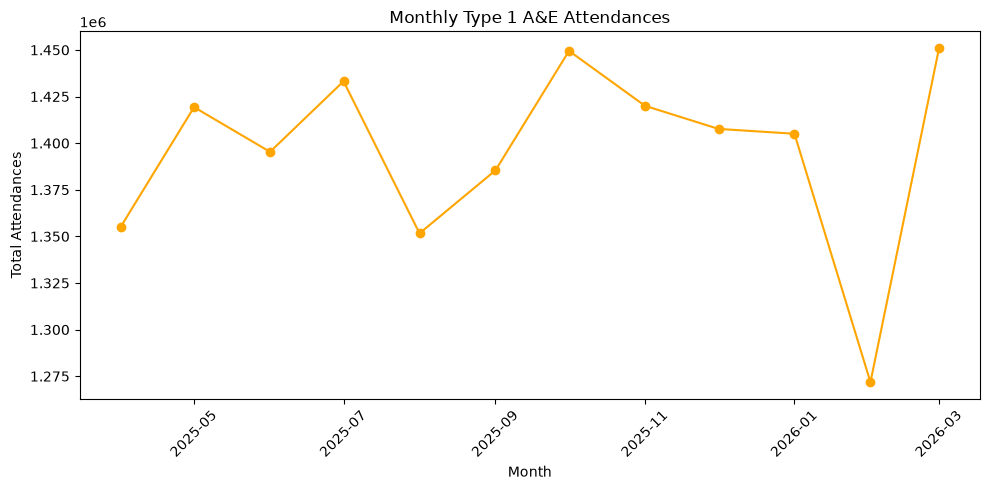

In [38]:
##creating charts
##monthly A&E attendance trends

plt.figure(figsize=(10, 5))
plt.plot(monthly_summary["month"], monthly_summary["total_attendances"], marker="o", color="orange")

plt.title("Monthly Type 1 A&E Attendances")
plt.xlabel("Month")
plt.ylabel("Total Attendances")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(r"C:\Users\HP\nhs_a&e_performance analysis/visuals/monthly_attendance_trend.png", dpi=300, bbox_inches="tight")

plt.show()

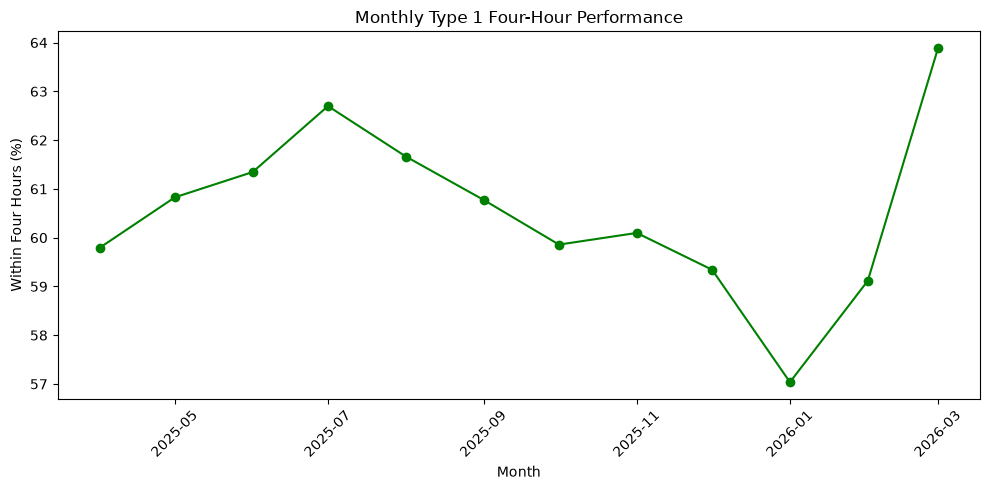

In [39]:
##monthly four-hour performance

plt.figure(figsize=(10, 5))

plt.plot(monthly_summary["month"], monthly_summary["within_4hrs_pct"], marker="o", color="green")

plt.title("Monthly Type 1 Four-Hour Performance")
plt.xlabel("Month")
plt.ylabel("Within Four Hours (%)")

plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig(r"C:\Users\HP\nhs_a&e_performance analysis/visuals/monthly_four_hour_performance.png", dpi=300, bbox_inches="tight")

plt.show()

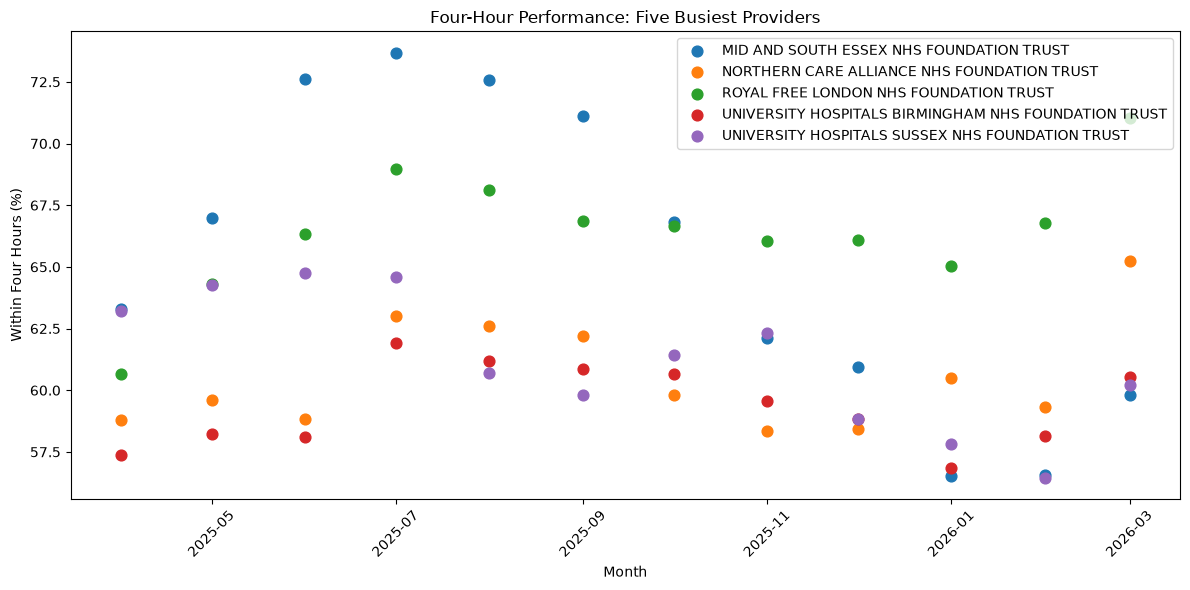

In [40]:
##compare 5 providers over time

top_5_codes = provider_summary.head(5)["org_code"]

top_5 = monthly[monthly["org_code"].isin(top_5_codes)]
top_5_codes = provider_summary.head(5)["org_code"]

top_5 = monthly[monthly["org_code"].isin(top_5_codes)]

plt.figure(figsize=(12, 6))

for provider, data in top_5.groupby("org_name"):
    plt.scatter(data["month"], data["within_4hrs_pct"], label=provider, alpha=1, s=60)

plt.title("Four-Hour Performance: Five Busiest Providers")
plt.xlabel("Month")
plt.ylabel("Within Four Hours (%)")

plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()

plt.savefig(r"C:\Users\HP\nhs_a&e_performance analysis/visuals/top_5_provider_trends.png", dpi=300, bbox_inches="tight")

plt.show()

In [41]:
monthly_summary.to_csv(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Processed/monthly_ae_summary.csv", index=False)

In [42]:
provider_summary.to_csv(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Processed/provider_annual_summary.csv", index=False)

In [43]:
monthly.to_csv(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Processed/monthly_ae_combined.csv", index=False)

In [44]:
monthly["month"] = pd.to_datetime(monthly["month"])

monthly_ae_dashboard = monthly[monthly["org_code"] != "TOTAL"].copy()
monthly.to_csv(r"C:\Users\HP\nhs_a&e_performance analysis/Data/Processed/monthly_ae_dashboard.csv", index=False)

print("Dashboard dataset saved successfully!")

Dashboard dataset saved successfully!


# Day 5: Monthly Trend and Provider Analysis

## Analysis performed
- Combined 12 monthly NHS datasets.
- Calculated monthly Type 1 attendance volumes.
- Calculated monthly four-hour performance.
- Compared provider performance over time.
- Used SQL aggregation, JOIN and LAG functions.

## Limitations
- Provider performance is not adjusted for differences in case mix.
- Monthly changes do not necessarily indicate long-term trends.
- Correlation does not establish causation.